# HQCM Change Classification: Pre-improvement Reproduction Run

Notebook này chạy lại phân loại HQCM với giao thức stratified 80/20, báo cáo metric trên đủ 8 nhãn, audit rò rỉ nhãn, thống kê prompt dài hơn 512 token và lưu kết quả để đối chiếu.

**Lưu ý về kết luận:** split 80/20 mới không phải split chính thức 4,611/518 dùng trong kết quả trước và paper. Kết quả có thể được gọi là *phù hợp với paper* khi so sánh chỉ số trong điều kiện tương đương; không thể khẳng định tái lập chính xác nếu paper không dùng cùng split, model checkpoint và cấu hình.

## 1. Import Required Libraries and Load Data

Chạy trên Kaggle GPU (T4 trở lên). Llama 2 là gated model: chấp nhận điều khoản trên Hugging Face và lưu token trong Kaggle Secrets với tên `HF_TOKEN`. Notebook tạo lại prompt bằng template chcl chính thức (diff + English commit summary); không dùng prediction hay adapter từ lần chạy trước.

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

ROOT = Path("/kaggle/working/codefuse-hqcm")
DATA_DIR = ROOT / "dataset"
RUN_DIR = Path("/kaggle/working/hqcm_reproduction_80_20")
SPLIT_DIR = RUN_DIR / "split"
ADAPTER_DIR = RUN_DIR / "llama2_7b_lora"
RUN_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

if not ROOT.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/codefuse-ai/codefuse-hqcm.git", str(ROOT)],
        check=True,
    )

%pip install -q transformers==4.46.1 datasets==3.1.0 accelerate==1.0.1 peft==0.13.2 bitsandbytes==0.44.1 python-dotenv==1.0.1 tensorboardX==2.6.2.2 scikit-learn==1.5.2 pandas==2.2.3

In [5]:
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/codefuse-hqcm")

print("Repo exists:", ROOT.exists())
print("Git folder exists:", (ROOT / ".git").exists())

result = subprocess.run(
    ["git", "-C", str(ROOT), "rev-parse", "HEAD"],
    capture_output=True,
    text=True,
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Repo exists: True
Git folder exists: True
Return code: 0
Output: ea7e7fab1bca176d9afd77350496649d7ca4743f

Error: 


In [6]:
REPO_COMMIT = subprocess.run(
    ["git", "-C", str(ROOT), "rev-parse", "HEAD"],
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()
print("HQCM source revision:", REPO_COMMIT)

HQCM source revision: ea7e7fab1bca176d9afd77350496649d7ca4743f


In [8]:
from pathlib import Path

ROOT = Path("/kaggle/working/codefuse-hqcm")

for filename in ["train.json", "test.json"]:
    matches = list(Path("/kaggle/working").rglob(filename))
    matches += list(Path("/kaggle/input").rglob(filename))

    print(f"\n{filename}:")
    for path in matches[:10]:
        print(path)


train.json:
/kaggle/working/codefuse-hqcm/dataset/train.json

test.json:
/kaggle/working/codefuse-hqcm/dataset/test.json


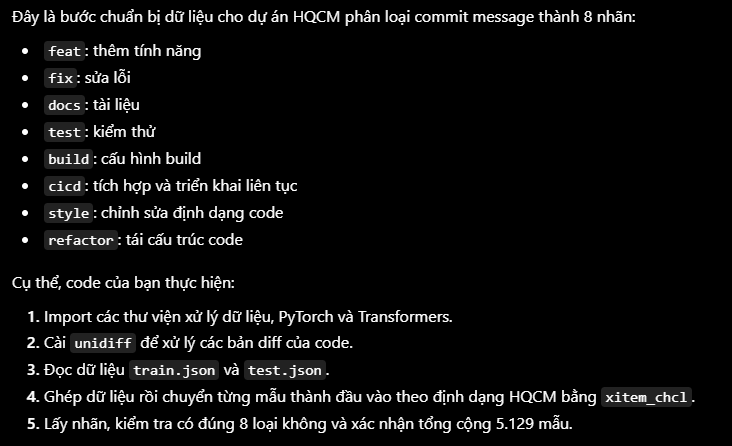

In [9]:
from pathlib import Path

ROOT = Path("/kaggle/working/codefuse-hqcm")
DATA_DIR = ROOT / "dataset"

print("DATA_DIR:", DATA_DIR)
print("Train exists:", (DATA_DIR / "train.json").exists())
print("Test exists:", (DATA_DIR / "test.json").exists())

DATA_DIR: /kaggle/working/codefuse-hqcm/dataset
Train exists: True
Test exists: True


In [10]:
import json
import re
import sys

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_recall_fscore_support,
)
from transformers import AutoTokenizer

sys.path.insert(0, str(ROOT))
%pip install -q unidiff==0.7.5
from hqcm.xdata import xitem_chcl

LABELS = ["style", "docs", "test", "build", "cicd", "fix", "feat", "refactor"]
SEED = 42
MAX_LENGTH = 512
MODEL_NAME = "meta-llama/Llama-2-7b-hf"

with (DATA_DIR / "train.json").open(encoding="utf-8") as f:
    original_train = json.load(f)
with (DATA_DIR / "test.json").open(encoding="utf-8") as f:
    original_test = json.load(f)

all_raw = original_train + original_test
unknown = sorted({row["type"] for row in all_raw} - set(LABELS))
assert not unknown, f"Found labels outside the eight HQCM classes: {unknown}"

# Reuse the official HQCM chcl prompt builder: diff + English commit summary.
all_rows = [xitem_chcl(row, fewshot=False) for row in all_raw]
all_labels = [str(row["answer"]).strip().lower() for row in all_rows]
assert len(all_rows) == 5129, f"Expected 5,129 examples, found {len(all_rows)}"
print(f"Loaded {len(original_train)} original-train + {len(original_test)} original-test = {len(all_rows)} examples")
print(pd.Series(all_labels).value_counts().reindex(LABELS, fill_value=0))

Note: you may need to restart the kernel to use updated packages.
Loaded 4611 original-train + 518 original-test = 5129 examples
style        101
docs         397
test         500
build        102
cicd         101
fix         1324
feat        1132
refactor    1472
Name: count, dtype: int64


## 2. Standardize Metrics: Macro on 8 Labels and Report Invalids

Macro precision/recall/F1 luôn tính trên danh sách cố định đủ 8 nhãn, kể cả lớp không được dự đoán. Accuracy tính trên toàn bộ mẫu; macro/micro/weighted chỉ xét 8 nhãn hợp lệ nên dự đoán invalid làm tăng false negative cho lớp thật. Số lượng và tỷ lệ invalid được báo cáo riêng.

In [11]:
INVALID = "__invalid__"
LABEL_PATTERN = re.compile(r"^\s*[\"'`*]*(style|docs|test|build|cicd|fix|feat|refactor)\b", re.IGNORECASE)


def parse_label(text):
    match = LABEL_PATTERN.match(str(text).strip())
    return match.group(1).lower() if match else INVALID


def calculate_metrics(gold, raw_predictions):
    pred = [parse_label(text) for text in raw_predictions]
    if not set(gold).issubset(set(LABELS)):
        raise ValueError("Ground truth contains a label outside the fixed eight-label set")
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        gold, pred, labels=LABELS, average="macro", zero_division=0
    )
    metrics = {
        "accuracy": float(accuracy_score(gold, pred)),
        "macro_precision_8": float(precision),
        "macro_recall_8": float(recall),
        "macro_f1_8": float(macro_f1),
        "micro_f1_8": float(f1_score(gold, pred, labels=LABELS, average="micro", zero_division=0)),
        "weighted_f1_8": float(f1_score(gold, pred, labels=LABELS, average="weighted", zero_division=0)),
        "invalid_count": int(sum(label == INVALID for label in pred)),
        "invalid_rate": float(sum(label == INVALID for label in pred) / len(pred)),
        "n_samples": len(gold),
    }
    return metrics, pred

# Small sanity check: invalid output lowers the scores and is counted separately.
_sanity, _ = calculate_metrics(["fix", "feat"], ["fix", "not a label"])
assert _sanity["invalid_count"] == 1 and _sanity["accuracy"] == 0.5
print("Metric helper sanity check: PASS")

Metric helper sanity check: PASS


## 3. Check for Label Leakage in Prompts

Template chính thức liệt kê cả tám tên nhãn để giải thích taxonomy; sự xuất hiện trong phần hướng dẫn đó không phải leakage. Audit bên dưới xét riêng dữ liệu từng mẫu: label tokens trong English summary/diff và mẫu rò rỉ mạnh hơn là summary bắt đầu theo Conventional Commit (`fix:`, `feat(scope):`, ...). Cần xem mẫu bị flag thủ công vì từ như “test” trong câu có thể là nội dung bình thường.

In [13]:
from pathlib import Path

RUN_DIR = Path("/kaggle/working/hqcm_run")
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("RUN_DIR:", RUN_DIR)

RUN_DIR: /kaggle/working/hqcm_run


In [14]:
def matching_labels(text):
    text = str(text).lower()
    return [label for label in LABELS if re.search(rf"(?<![a-z]){re.escape(label)}(?![a-z])", text)]


def is_conventional_commit_prefix(summary):
    return bool(re.match(
        r"^\s*(?:style|docs|test|build|cicd|fix|feat|refactor)(?:\([^)]*\))?!?:\s*",
        str(summary),
        flags=re.IGNORECASE,
    ))

leakage_rows = []
for idx, raw in enumerate(all_raw):
    summary = raw["summaries"]["en"]
    diff = raw["change"]
    prefix_leak = is_conventional_commit_prefix(summary)
    if prefix_leak or matching_labels(summary) or matching_labels(diff):
        leakage_rows.append({
            "index": idx,
            "gold_label": raw["type"],
            "summary": summary,
            "labels_in_summary": matching_labels(summary),
            "labels_in_diff": matching_labels(diff),
            "conventional_commit_prefix": prefix_leak,
        })

prefix_count = sum(row["conventional_commit_prefix"] for row in leakage_rows)
print(f"Rows with a valid label token in summary and/or diff: {len(leakage_rows)} / {len(all_raw)}")
print(f"Rows with an explicit Conventional Commit label prefix: {prefix_count} / {len(all_raw)}")
print("Flagged examples (up to 10):")
for row in leakage_rows[:10]:
    print({k: row[k] for k in ("index", "gold_label", "summary", "labels_in_summary", "conventional_commit_prefix")})

with (RUN_DIR / "label_leakage_audit.json").open("w", encoding="utf-8") as f:
    json.dump(leakage_rows, f, ensure_ascii=False, indent=2)

Rows with a valid label token in summary and/or diff: 1206 / 5129
Rows with an explicit Conventional Commit label prefix: 0 / 5129
Flagged examples (up to 10):
{'index': 3, 'gold_label': 'fix', 'summary': 'Fix the case where the array length is 0', 'labels_in_summary': ['fix'], 'conventional_commit_prefix': False}
{'index': 7, 'gold_label': 'feat', 'summary': 'Add elasticsearch-mapper-size plugin', 'labels_in_summary': [], 'conventional_commit_prefix': False}
{'index': 13, 'gold_label': 'build', 'summary': 'Add ben-manes.versions to find updated versions of dependency libraries', 'labels_in_summary': [], 'conventional_commit_prefix': False}
{'index': 17, 'gold_label': 'test', 'summary': 'Add missing Javadoc', 'labels_in_summary': [], 'conventional_commit_prefix': False}
{'index': 21, 'gold_label': 'docs', 'summary': 'Add Javadoc for the new `FileHandlerSpec.files()` convenience method', 'labels_in_summary': [], 'conventional_commit_prefix': False}
{'index': 27, 'gold_label': 'build', '

## 4. Stratified Split (80/20)

Gộp official train/test rồi tạo một split stratified 80/20 (`random_state=42`), vì vậy đây là một evaluation protocol mới chứ không cùng test set chính thức của paper. Các ví dụ được gán đúng một lần; train/test không được dùng để tinh chỉnh chéo sau khi xem test score.

In [16]:
from pathlib import Path

SPLIT_DIR = RUN_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

print("SPLIT_DIR:", SPLIT_DIR)

SPLIT_DIR: /kaggle/working/hqcm_run/splits


In [17]:
train_rows, test_rows, y_train, y_test = train_test_split(
    all_rows,
    all_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=all_labels,
)

for split_name, split_labels in (("train", y_train), ("test", y_test)):
    counts = pd.Series(split_labels).value_counts().reindex(LABELS, fill_value=0)
    print(f"\n{split_name}: {len(split_labels)} samples")
    print(counts)
    assert (counts > 0).all(), f"At least one label is absent from {split_name}"

for name, rows in (("train", train_rows), ("test", test_rows)):
    with (SPLIT_DIR / f"{name}.json").open("w", encoding="utf-8") as f:
        json.dump(rows, f, ensure_ascii=False, indent=2)

split_manifest = {
    "protocol": "stratified 80/20 from official train+test combined",
    "seed": SEED,
    "total": len(all_rows),
    "train": len(train_rows),
    "test": len(test_rows),
    "labels": LABELS,
}
with (RUN_DIR / "split_manifest.json").open("w", encoding="utf-8") as f:
    json.dump(split_manifest, f, ensure_ascii=False, indent=2)
print("Split files and manifest saved under:", RUN_DIR)


train: 4103 samples
style         81
docs         318
test         400
build         82
cicd          81
fix         1059
feat         905
refactor    1177
Name: count, dtype: int64

test: 1026 samples
style        20
docs         79
test        100
build        20
cicd         20
fix         265
feat        227
refactor    295
Name: count, dtype: int64
Split files and manifest saved under: /kaggle/working/hqcm_run


## 5. Count Prompts Exceeding 512 Tokens in Train and Test Sets

Đếm số token của prompt nguyên bản (có special tokens), trước truncation, bằng tokenizer Llama 2. Tỷ lệ này là diagnostic input-only; lúc SFT sẽ dành chỗ cho answer và EOS trước khi cắt phần đầu prompt, để nhãn mục tiêu không bị mất.

In [29]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("kaggle-llama")

print("Đã lấy secret thành công:", bool(secret_value_0))

Đã lấy secret thành công: True


In [30]:
import os
from huggingface_hub import login
from transformers import AutoTokenizer

HF_TOKEN = secret_value_0

# Dùng tên biến môi trường chuẩn, không dùng token làm tên biến
os.environ["HF_TOKEN"] = HF_TOKEN

login(token=HF_TOKEN, add_to_git_credential=False)

MODEL_NAME = "meta-llama/Llama-2-7b-hf"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=HF_TOKEN,
)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded successfully!")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


tokenizer_config.json:   0%|          | 0.00/776 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [31]:
# from kaggle_secrets import UserSecretsClient
# from huggingface_hub import login

# HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
# assert HF_TOKEN, "Add a Hugging Face access token to Kaggle Secrets as HF_TOKEN"
# os.environ["HF_TOKEN"] = HF_TOKEN
# login(token=HF_TOKEN, add_to_git_credential=False)

# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_TOKEN)
# if tokenizer.pad_token_id is None:
#     tokenizer.pad_token = tokenizer.eos_token


# def prompt_token_count(prompt):
#     return len(tokenizer(prompt, add_special_tokens=True, truncation=False)["input_ids"])

# length_rows = []
# for split_name, rows in (("train", train_rows), ("test", test_rows)):
#     lengths = [prompt_token_count(row["prompt"]) for row in rows]
#     over = sum(length > MAX_LENGTH for length in lengths)
#     result = {
#         "split": split_name,
#         "samples": len(lengths),
#         "over_512": over,
#         "over_512_rate": over / len(lengths),
#         "mean_tokens": float(np.mean(lengths)),
#         "median_tokens": float(np.median(lengths)),
#         "max_tokens": int(max(lengths)),
#     }
#     length_rows.append(result)
#     print(result)

# pd.DataFrame(length_rows).to_csv(RUN_DIR / "prompt_length_summary.csv", index=False)

BackendError: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 140989360 and label HF_TOKEN.'], 'error': {'code': 5}, 'wasSuccessful': False}.

In [32]:
def prompt_token_count(prompt):
    return len(
        tokenizer(
            prompt,
            add_special_tokens=True,
            truncation=False,
        )["input_ids"]
    )

In [33]:
length_rows = []

for split_name, rows in (
    ("train", train_rows),
    ("test", test_rows),
):
    lengths = [
        prompt_token_count(row["prompt"])
        for row in rows
    ]

    over = sum(length > MAX_LENGTH for length in lengths)

    item = {
        "split": split_name,
        "samples": len(lengths),
        "over_512": over,
        "over_512_rate": over / len(lengths),
        "mean_tokens": float(np.mean(lengths)),
        "median_tokens": float(np.median(lengths)),
        "max_tokens": int(max(lengths)),
    }

    length_rows.append(item)
    print(item)

{'split': 'train', 'samples': 4103, 'over_512': 4102, 'over_512_rate': 0.999756275895686, 'mean_tokens': 735.3904460151109, 'median_tokens': 711.0, 'max_tokens': 2278}
{'split': 'test', 'samples': 1026, 'over_512': 1026, 'over_512_rate': 1.0, 'mean_tokens': 734.7222222222222, 'median_tokens': 706.0, 'max_tokens': 3198}


## 6. Model Training and Evaluation

Cell này chỉ sửa bản clone trong Kaggle working directory: nạp split JSON cục bộ, giới hạn worker, dùng FP16 cho GPU Kaggle phổ biến, và thay preprocessing để luôn giữ answer/EOS trong 512 token. Cấu hình còn lại bám lần chạy Llama-2-7B LoRA trước (5 epochs, rank 64, 4-bit NF4, seed 0). Huấn luyện cần GPU và quyền tải model.

In [34]:
import ast

SFT_FILE = ROOT / "hqcm" / "sft.py"
source = SFT_FILE.read_text(encoding="utf-8")

old_loader = "raw_dataset = load_dataset(arg_dataset, opt_dataset_config, split=opt_dataset_split)"
new_loader = '''raw_dataset = load_dataset(
    "json",
    data_files={opt_dataset_split: os.path.join(arg_dataset, f"{opt_dataset_split}.json")},
    split=opt_dataset_split
)'''
assert source.count(old_loader) == 1, "Expected one official dataset loader statement"
source = source.replace(old_loader, new_loader)
source = source.replace("opt_num_proc = os.cpu_count()", "opt_num_proc = min(os.cpu_count() or 2, 4)")
source = source.replace("bnb_4bit_compute_dtype=torch.bfloat16", "bnb_4bit_compute_dtype=torch.float16")
source = source.replace("bf16=True,  # Enforce bf16 precision", "bf16=False,\n    fp16=True,")

module = ast.parse(source)
preprocess_nodes = [
    node for node in module.body
    if isinstance(node, ast.FunctionDef) and node.name == "tokenize_and_preprocess"
]
assert len(preprocess_nodes) == 1, "Expected one tokenize_and_preprocess function"
node = preprocess_nodes[0]
replacement = '''def tokenize_and_preprocess(example):
    prompt_ids = tokenizer(example["prompt"], add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(example["answer"], add_special_tokens=False)["input_ids"]
    max_len = opt_dataset_max_seq_len
    bos_ids = [tokenizer.bos_token_id] if tokenizer.bos_token_id is not None else []
    eos_ids = [tokenizer.eos_token_id] if tokenizer.eos_token_id is not None else []

    answer_budget = max_len - len(bos_ids) - len(eos_ids)
    answer_ids = answer_ids[:max(0, answer_budget)]
    prompt_budget = max_len - len(bos_ids) - len(answer_ids) - len(eos_ids)
    prompt_ids = prompt_ids[-prompt_budget:] if prompt_budget > 0 else []

    input_ids = bos_ids + prompt_ids + answer_ids + eos_ids
    labels = ([-100] * (len(bos_ids) + len(prompt_ids))) + answer_ids + eos_ids
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }
'''
lines = source.splitlines(keepends=True)
source = "".join(lines[:node.lineno - 1]) + replacement + "\n" + "".join(lines[node.end_lineno:])
ast.parse(source)
SFT_FILE.write_text(source, encoding="utf-8")

for check in (new_loader, "fp16=True", "answer_ids = answer_ids[:max(0, answer_budget)]"):
    assert check in source, f"Patch verification failed: {check}"
print("Patched SFT script in Kaggle clone:", SFT_FILE)
print("Syntax and patch checks: PASS")

Patched SFT script in Kaggle clone: /kaggle/working/codefuse-hqcm/hqcm/sft.py
Syntax and patch checks: PASS


In [ ]:
from pathlib import Path

RUN_DIR = Path("/kaggle/working/hqcm_run")
ADAPTER_DIR = RUN_DIR / "adapter"

RUN_DIR.mkdir(parents=True, exist_ok=True)

print("ADAPTER_DIR:", ADAPTER_DIR)
print("Directory exists:", ADAPTER_DIR.exists())

In [38]:
assert not ADAPTER_DIR.exists(), (
    f"Training output already exists at {ADAPTER_DIR}; choose a fresh run directory "
    "to avoid silently mixing checkpoints."
)

print("Output directory check: PASS")

Output directory check: PASS


In [41]:
%pip install -U bitsandbytes

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 89.7 MB/s  0:00:006m0:00:01:01
  Attempting uninstall: bitsandbytes
    Found existing installation: bitsandbytes 0.44.1
    Uninstalling bitsandbytes-0.44.1:
      Successfully uninstalled bitsandbytes-0.44.1
Note: you may need to restart the kernel to use updated packages.


lệnh bắt đầu **train (fine-tune) model Llama 2** trên Kaggle bằng phương pháp LoRA kết hợp quantization 4-bit.
**Bước 1:** Tải model Llama 2
**Bước 2:** Nạp model và chuẩn bị LoRA
**Bước 3:** Fine-tune model (Học từ 4.103 mẫu train trong 5 epoch theo cấu hình hiện tại.)


In [42]:
os.chdir(ROOT)
train_command = [
    sys.executable, "-m", "hqcm.sft", MODEL_NAME,
    "--dataset", str(SPLIT_DIR), "--split", "train",
    "--max-length", str(MAX_LENGTH), "--output", str(ADAPTER_DIR),
    "--seed", "0", "--learning-rate", "2e-4", "--num-epochs", "5",
    "--batch-size", "1", "--micro-batch-size", "1",
    "--lora-rank", "64", "--lora-alpha", "16", "--lora-dropout", "0.1",
    "--quantization", "4",
]
print("Training command:", " ".join(train_command))
subprocess.run(train_command, check=True, env=os.environ.copy())
print("Training completed:", ADAPTER_DIR)

Training command: /usr/bin/python3 -m hqcm.sft meta-llama/Llama-2-7b-hf --dataset /kaggle/working/hqcm_run/splits --split train --max-length 512 --output /kaggle/working/hqcm_run/adapter --seed 0 --learning-rate 2e-4 --num-epochs 5 --batch-size 1 --micro-batch-size 1 --lora-rank 64 --lora-alpha 16 --lora-dropout 0.1 --quantization 4
{'batch_size': 1,
 'config': None,
 'dataset': '/kaggle/working/hqcm_run/splits',
 'learning_rate': 0.0002,
 'lora_alpha': 16,
 'lora_dropout': 0.1,
 'lora_rank': 64,
 'max_length': 512,
 'micro_batch_size': 1,
 'model': 'meta-llama/Llama-2-7b-hf',
 'no_lora': False,
 'num_epochs': 5,
 'output': '/kaggle/working/hqcm_run/adapter',
 'percentage': 100,
 'quantization': 4,
 'resume': False,
 'seed': 0,
 'split': 'train'}


  4%|▍         | 780/20515 [15:24<6:30:30,  1.19s/it]

{'loss': 6.5002, 'grad_norm': nan, 'learning_rate': 0.0, 'epoch': 0.0}
{'loss': 7.3529, 'grad_norm': 3.4710376262664795, 'learning_rate': 7.766990291262136e-06, 'epoch': 0.0}
{'loss': 8.0374, 'grad_norm': 3.867823839187622, 'learning_rate': 1.7475728155339808e-05, 'epoch': 0.0}
{'loss': 6.7116, 'grad_norm': 2.511073589324951, 'learning_rate': 2.6213592233009708e-05, 'epoch': 0.01}
{'loss': 5.0504, 'grad_norm': 5.437826633453369, 'learning_rate': 3.592233009708738e-05, 'epoch': 0.01}
{'loss': 3.6291, 'grad_norm': 2.6753628253936768, 'learning_rate': 4.5631067961165054e-05, 'epoch': 0.01}
{'loss': 2.024, 'grad_norm': 4.644820213317871, 'learning_rate': 5.533980582524272e-05, 'epoch': 0.01}
{'loss': 1.145, 'grad_norm': 3.723172187805176, 'learning_rate': 6.504854368932039e-05, 'epoch': 0.02}
{'loss': 1.398, 'grad_norm': 5.358027935028076, 'learning_rate': 7.475728155339806e-05, 'epoch': 0.02}
{'loss': 0.7261, 'grad_norm': 3.3677291870117188, 'learning_rate': 8.446601941747573e-05, 'epoch'

  8%|▊         | 1560/20515 [30:53<6:14:45,  1.19s/it]


{'loss': 0.4089, 'grad_norm': 3.9545061588287354, 'learning_rate': 0.0001942783987394751, 'epoch': 0.19}
{'loss': 0.3173, 'grad_norm': 0.3706209361553192, 'learning_rate': 0.0001941799202324093, 'epoch': 0.19}
{'loss': 0.4439, 'grad_norm': 4.958811283111572, 'learning_rate': 0.00019408144172534345, 'epoch': 0.2}
{'loss': 0.1839, 'grad_norm': 0.18071024119853973, 'learning_rate': 0.00019398296321827761, 'epoch': 0.2}
{'loss': 0.3648, 'grad_norm': 4.210906028747559, 'learning_rate': 0.00019388448471121178, 'epoch': 0.2}
{'loss': 1.0296, 'grad_norm': 2.8068883419036865, 'learning_rate': 0.00019378600620414597, 'epoch': 0.2}
{'loss': 0.8394, 'grad_norm': 1.5392786264419556, 'learning_rate': 0.00019368752769708013, 'epoch': 0.21}
{'loss': 0.5626, 'grad_norm': 0.08430705964565277, 'learning_rate': 0.0001935890491900143, 'epoch': 0.21}
{'loss': 0.6045, 'grad_norm': 3.032500982284546, 'learning_rate': 0.00019349057068294845, 'epoch': 0.21}
{'loss': 0.4372, 'grad_norm': 0.11517033725976944, 'l

...


{'loss': 0.0002, 'grad_norm': 0.01984195038676262, 'learning_rate': 1.7676892018317004e-05, 'epoch': 4.56}
{'loss': 0.0001, 'grad_norm': 0.002608981914818287, 'learning_rate': 1.757841351125117e-05, 'epoch': 4.57}
{'loss': 0.0, 'grad_norm': 1.6727586626075208e-05, 'learning_rate': 1.747993500418534e-05, 'epoch': 4.57}
{'loss': 0.0, 'grad_norm': 0.00014219895820133388, 'learning_rate': 1.7381456497119506e-05, 'epoch': 4.57}
{'loss': 0.0001, 'grad_norm': 0.1394502818584442, 'learning_rate': 1.7282977990053672e-05, 'epoch': 4.57}
{'loss': 0.0, 'grad_norm': 0.0005988217890262604, 'learning_rate': 1.718449948298784e-05, 'epoch': 4.58}
{'loss': 0.0, 'grad_norm': 0.0001836616575019434, 'learning_rate': 1.7086020975922007e-05, 'epoch': 4.58}
{'loss': 0.0, 'grad_norm': 0.00011338562035234645, 'learning_rate': 1.6987542468856173e-05, 'epoch': 4.58}
{'loss': 0.0017, 'grad_norm': 2.9464981707860716e-05, 'learning_rate': 1.6889063961790343e-05, 'epoch': 4.58}
{'loss': 0.0002, 'grad_norm': 8.039873

 99%|█████████▉| 20260/20515 [6:36:43<04:50,  1.14s/it]


{'loss': 0.0001, 'grad_norm': 0.00022303346486296505, 'learning_rate': 1.0103894824954454e-05, 'epoch': 4.75}
{'loss': 0.0001, 'grad_norm': 4.760641240864061e-05, 'learning_rate': 1.0005416317888622e-05, 'epoch': 4.76}
{'loss': 0.0, 'grad_norm': 4.75745000585448e-05, 'learning_rate': 9.90693781082279e-06, 'epoch': 4.76}
{'loss': 0.0, 'grad_norm': 0.0009268027497455478, 'learning_rate': 9.808459303756956e-06, 'epoch': 4.76}
{'loss': 0.0012, 'grad_norm': 0.004234034568071365, 'learning_rate': 9.709980796691123e-06, 'epoch': 4.76}
{'loss': 0.0001, 'grad_norm': 0.0096683194860816, 'learning_rate': 9.611502289625291e-06, 'epoch': 4.76}
{'loss': 0.0015, 'grad_norm': 0.8999012112617493, 'learning_rate': 9.513023782559455e-06, 'epoch': 4.77}
{'loss': 0.0001, 'grad_norm': 5.95796991547104e-05, 'learning_rate': 9.414545275493623e-06, 'epoch': 4.77}
{'loss': 0.0013, 'grad_norm': 1.8685124814510345e-05, 'learning_rate': 9.31606676842779e-06, 'epoch': 4.77}
{'loss': 0.0001, 'grad_norm': 0.00069958

100%|██████████| 20515/20515 [6:41:38<00:00,  1.17s/it]



{'loss': 0.0, 'grad_norm': 0.0006480226293206215, 'learning_rate': 2.521049780885322e-06, 'epoch': 4.94}
{'loss': 0.0, 'grad_norm': 0.0024791574105620384, 'learning_rate': 2.4225712738194893e-06, 'epoch': 4.94}
{'loss': 0.0058, 'grad_norm': 0.00020920434326399118, 'learning_rate': 2.324092766753656e-06, 'epoch': 4.95}
{'loss': 0.0, 'grad_norm': 0.00018549663946032524, 'learning_rate': 2.225614259687823e-06, 'epoch': 4.95}
{'loss': 0.0001, 'grad_norm': 0.00021043392189312726, 'learning_rate': 2.1271357526219903e-06, 'epoch': 4.95}
{'loss': 0.0, 'grad_norm': 0.00011574148084037006, 'learning_rate': 2.0286572455561576e-06, 'epoch': 4.95}
{'loss': 0.3017, 'grad_norm': 1.3025020962231793e-05, 'learning_rate': 1.930178738490325e-06, 'epoch': 4.95}
{'loss': 0.0, 'grad_norm': 9.750868048286065e-05, 'learning_rate': 1.831700231424492e-06, 'epoch': 4.96}
{'loss': 0.0147, 'grad_norm': 0.08887116611003876, 'learning_rate': 1.733221724358659e-06, 'epoch': 4.96}
{'loss': 0.0, 'grad_norm': 8.3682234

In [43]:
import shutil
from pathlib import Path

RUN_DIR = Path("/kaggle/working/hqcm_run")
ZIP_BASE = Path("/kaggle/working/hqcm_run_backup")

assert RUN_DIR.exists(), f"Không tìm thấy thư mục: {RUN_DIR}"

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir="/kaggle/working",
    base_dir="hqcm_run",
)

print("Đã nén thành công:", zip_path)
print("Kích thước: %.2f GB" % (Path(zip_path).stat().st_size / (1024**3)))

Đã nén thành công: /kaggle/working/hqcm_run_backup.zip
Kích thước: 1.84 GB


In [46]:
import shutil
from pathlib import Path

ADAPTER_DIR = Path("/kaggle/working/hqcm_run/adapter")
ZIP_PATH = "/kaggle/working/hqcm_adapter.zip"

assert ADAPTER_DIR.exists(), "Không tìm thấy thư mục adapter"

shutil.make_archive(
    "/kaggle/working/hqcm_adapter",
    "zip",
    root_dir=ADAPTER_DIR,
)

size_mb = Path(ZIP_PATH).stat().st_size / (1024**2)
print(f"File: {ZIP_PATH}")
print(f"Kích thước: {size_mb:.1f} MB")

File: /kaggle/working/hqcm_adapter.zip
Kích thước: 1880.9 MB


Đánh giá model sau khi train xong. Tải model Llama 2 cùng adapter LoRA mà bạn vừa huấn luyện, chạy dự đoán trên tập test gồm 1.026 mẫu, rồi lưu các dự đoán vào biến raw_predictions để chuẩn bị tính các chỉ số đánh giá.
**Bước 1:** Kiểm tra model đã train (Xác nhận Kaggle đang có GPU và thư mục adapter chứa adapter_config.json.)
**Bước 2:** Nạp model (Tải Llama 2 7B ở dạng 4-bit rồi gắn adapter LoRA đã train. Cách này giảm nhu cầu VRAM.)
**Bước 3: **Dự đoán tập test (Đưa từng prompt vào model, sinh tối đa 16 token và lưu kết quả vào raw_predictions.)
**Bước 4:** Giải phóng bộ nhớ (Xóa biến base_model và yêu cầu CUDA giải phóng bộ nhớ cache sau khi dự đoán.)

In [45]:
from peft import PeftModel
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert torch.cuda.is_available(), "Enable a Kaggle GPU before loading the 7B model"
assert (ADAPTER_DIR / "adapter_config.json").is_file(), "Adapter not found; run the training cell first"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_TOKEN)
tokenizer.truncation_side = "left"
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    token=HF_TOKEN,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
)
model = PeftModel.from_pretrained(base_model, str(ADAPTER_DIR))
model.eval()

with (SPLIT_DIR / "test.json").open(encoding="utf-8") as f:
    eval_rows = json.load(f)
eval_gold = [str(row["answer"]).strip().lower() for row in eval_rows]
raw_predictions = []

for index, row in enumerate(eval_rows, start=1):
    encoded = tokenizer(
        row["prompt"], return_tensors="pt", truncation=True, max_length=MAX_LENGTH
    ).to(model.device)
    with torch.inference_mode():
        generated = model.generate(
            **encoded,
            do_sample=False,
            num_beams=1,
            max_new_tokens=16,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    new_tokens = generated[0, encoded["input_ids"].shape[1]:]
    raw_predictions.append(tokenizer.decode(new_tokens, skip_special_tokens=True).strip())
    if index % 100 == 0 or index == len(eval_rows):
        print(f"Generated {index}/{len(eval_rows)}")

del base_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


Generated 100/1026
Generated 200/1026
Generated 300/1026
Generated 400/1026
Generated 500/1026
Generated 600/1026
Generated 700/1026
Generated 800/1026
Generated 900/1026
Generated 1000/1026
Generated 1026/1026


In [47]:
eval_metrics, eval_labels = calculate_metrics(eval_gold, raw_predictions)
print("=== Standardized 80/20 test metrics ===")
for key, value in eval_metrics.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

print("\nPer-class report (fixed eight labels):")
print(classification_report(
    eval_gold,
    eval_labels,
    labels=LABELS,
    target_names=LABELS,
    zero_division=0,
    digits=4,
))

prediction_rows = []
for row, gold, raw, pred in zip(eval_rows, eval_gold, raw_predictions, eval_labels):
    prediction_rows.append({
        "prompt": row["prompt"],
        "gold_label": gold,
        "raw_generation": raw,
        "predicted_label": pred,
        "invalid": pred == INVALID,
        "correct": pred == gold,
    })
with (RUN_DIR / "predictions_80_20.json").open("w", encoding="utf-8") as f:
    json.dump(prediction_rows, f, ensure_ascii=False, indent=2)
with (RUN_DIR / "metrics_80_20.json").open("w", encoding="utf-8") as f:
    json.dump(eval_metrics, f, ensure_ascii=False, indent=2)
print("Saved predictions and metrics under:", RUN_DIR)

=== Standardized 80/20 test metrics ===
accuracy: 0.6326
macro_precision_8: 0.7271
macro_recall_8: 0.7489
macro_f1_8: 0.7311
micro_f1_8: 0.6326
weighted_f1_8: 0.5643
invalid_count: 0
invalid_rate: 0.0000
n_samples: 1026

Per-class report (fixed eight labels):
              precision    recall  f1-score   support

       style     0.9412    0.8000    0.8649        20
        docs     0.9178    0.8481    0.8816        79
        test     0.8319    0.9400    0.8826       100
       build     1.0000    0.9000    0.9474        20
        cicd     1.0000    0.9500    0.9744        20
         fix     0.4700    0.7698    0.5837       265
        feat     0.0000    0.0000    0.0000       227
    refactor     0.6562    0.7831    0.7141       295

    accuracy                         0.6326      1026
   macro avg     0.7271    0.7489    0.7311      1026
weighted avg     0.5192    0.6326    0.5643      1026

Saved predictions and metrics under: /kaggle/working/hqcm_run


## 7. Compare Results with Paper

Paper reference được điền theo số trích: Macro-F1 = 0.810, Micro-F1 = 0.759. Accuracy reference chưa có trong các số này. Với phân loại single-label và không có invalid, micro-F1 bằng accuracy; tuy nhiên vẫn báo cáo riêng, nhất là khi có invalid output. Sai khác split, model revision hoặc training recipe sẽ được ghi nhận; điểm gần nhau là bằng chứng tương thích, không tự động chứng minh tái lập chính xác.

In [48]:
PAPER_MACRO_F1 = 0.810
PAPER_MICRO_F1 = 0.759
TOLERANCE = 0.02

comparison = pd.DataFrame([
    {"metric": "Macro-F1 (8 labels)", "paper_reference": PAPER_MACRO_F1,
     "this_80_20_run": eval_metrics["macro_f1_8"], "previous_90_10_run": 0.841},
    {"metric": "Micro-F1 (8 valid labels)", "paper_reference": PAPER_MICRO_F1,
     "this_80_20_run": eval_metrics["micro_f1_8"], "previous_90_10_run": np.nan},
    {"metric": "Accuracy", "paper_reference": np.nan,
     "this_80_20_run": eval_metrics["accuracy"], "previous_90_10_run": 0.7761},
])
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
comparison.to_csv(RUN_DIR / "paper_comparison.csv", index=False)

macro_close = abs(eval_metrics["macro_f1_8"] - PAPER_MACRO_F1) <= TOLERANCE
micro_close = abs(eval_metrics["micro_f1_8"] - PAPER_MICRO_F1) <= TOLERANCE
print("\n=== Interpretation ===")
if prefix_count:
    print(f"Do not claim reproduction: found {prefix_count} summaries with an explicit label prefix; review leakage audit first.")
elif macro_close and micro_close:
    print("Metrics are within the configured 0.02 tolerance of the quoted paper values on this new split.")
else:
    print("At least one reported F1 differs from the quoted paper value by more than 0.02 on this split.")
print("This is a comparable 80/20 result, not an exact successful reproduction: the split differs from the paper/original 4,611/518 split, and exact model revision and paper recipe must also match before making that claim.")
print("Invalid outputs:", f"{eval_metrics['invalid_count']}/{eval_metrics['n_samples']} ({eval_metrics['invalid_rate']:.2%})")
print("Artifacts:", RUN_DIR)

                   metric  paper_reference  this_80_20_run  previous_90_10_run
      Macro-F1 (8 labels)           0.8100          0.7311              0.8410
Micro-F1 (8 valid labels)           0.7590          0.6326                 NaN
                 Accuracy              NaN          0.6326              0.7761

=== Interpretation ===
At least one reported F1 differs from the quoted paper value by more than 0.02 on this split.
This is a comparable 80/20 result, not an exact successful reproduction: the split differs from the paper/original 4,611/518 split, and exact model revision and paper recipe must also match before making that claim.
Invalid outputs: 0/1026 (0.00%)
Artifacts: /kaggle/working/hqcm_run


In [49]:
run_metadata = {
    **split_manifest,
    "hqcm_repo_commit": REPO_COMMIT,
    "model_name": MODEL_NAME,
    "model_revision": tokenizer.init_kwargs.get("_commit_hash"),
    "max_length": MAX_LENGTH,
    "epochs": 5,
    "lora_rank": 64,
    "quantization": "4-bit NF4 / FP16 compute",
    "training_seed": 0,
    "generation": "greedy, max_new_tokens=16",
    "paper_comparison_tolerance": TOLERANCE,
}
with (RUN_DIR / "reproduction_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(run_metadata, f, ensure_ascii=False, indent=2)
print("Reproduction metadata saved:", RUN_DIR / "reproduction_metadata.json")

Reproduction metadata saved: /kaggle/working/hqcm_run/reproduction_metadata.json
